# SalesOps Control Tower: activation SLAs, POS inventory and payment reconciliation

A small, reproducible case study built around the SalesOps Analyst role at Bold. It simulates the order-to-cash cycle of POS terminals sold to small merchants in Colombia and answers three operational questions:

1. **Activation SLA.** Where does time get lost between payment and the merchant's first transaction: KYC, dispatch, carrier, or the merchant?
2. **POS inventory.** Which devices are stuck in transit or delivered but never activated?
3. **Reconciliation.** Which orders have invoice and bank collection that do not match, and how many pesos are involved?

**Important.** All data is synthetic and generated in this notebook. It is a scenario inspired by the job posting, not Bold data, and it makes no claims about Bold's real systems, volumes or problems. Device names and prices are illustrative placeholders.

**How it is organised**

| Step | What happens |
|---|---|
| 1 | Generate four source tables (CRM orders, WMS logistics, invoices, bank collections) with a known number of injected anomalies |
| 2 | Load them into SQLite and audit SLAs and reconciliation with SQL |
| 3 | Check that the pipeline finds the anomalies we planted |
| 4 | KPIs and charts |
| 5 | Exception report in Excel (one tab per owning team) plus a ticket text for every exception |

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---- Scenario parameters: change any of these, re-run, and everything updates ----
SEED = 42
N_ORDERS = 1_500
AS_OF_DATE = pd.Timestamp("2026-10-30")   # fixed "today" so results are reproducible

SLA_TARGET_BDAYS = 4      # payment -> first transaction, in business days
SLA_SEVERE_BDAYS = 6      # what we call a severe delay
ZOMBIE_AFTER_DAYS = 15    # delivered but still not activated (calendar days)
STALL_AFTER_DAYS = 5      # in transit with no carrier update (calendar days)
KYC_OVERDUE_BDAYS = 3     # KYC pending for longer than this is an exception
RECON_WINDOW_DAYS = 3     # time we give the bank before an unpaid invoice is an exception

# ---- Anomalies we inject on purpose (exact counts, so we can verify the pipeline finds them) ----
SHARE_MID_CITY_DELAYED = 0.18
N_ZOMBIES = 65
N_STALLED = 22
RECON_MIX = {"partial": 24, "duplicate": 14, "reversal": 12, "no_collection": 8, "no_invoice": 5}
N_RECON_EXCEPTIONS = sum(RECON_MIX.values())   # 63 = 4.2% of 1,500

# Illustrative placeholders, NOT official prices. Check bold.co before quoting real figures.
POS_PRICES_COP = {"Bold Neo": 79_000, "Bold Plus": 99_000, "Bold Smart": 129_000}

MAJOR_CITIES = ["Bogotá", "Medellín", "Cali", "Barranquilla"]
MID_CITIES = ["Neiva", "Bucaramanga", "Pereira", "Pasto"]
CARRIERS = ["Servientrega", "Coordinadora", "Inter Rapidísimo"]

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)   # one random generator for everything -> reproducible

## 1. Synthetic data

Each order passes through five dated steps: **payment, KYC decision, dispatch, carrier delivery, first transaction**. We build those dates first (in business days), then cut off anything after `AS_OF_DATE`, so recent orders are naturally "still in progress" instead of having impossible future dates.

Then we plant the anomalies with exact counts. Planting exact numbers matters: later we check that the SQL finds exactly what we hid.

In [2]:
n = N_ORDERS
as_of_d = AS_OF_DATE.to_datetime64().astype("datetime64[D]")

# ---------- who bought what ----------
order_id = np.array([f"ORD-{i:05d}" for i in range(1, n + 1)])
merchant_id = np.array([f"MRC-{10000 + i}" for i in range(n)])   # one order per merchant (simplification)
city_tier = rng.choice(["major", "intermediate"], n, p=[0.70, 0.30])
is_mid = city_tier == "intermediate"
city = np.where(is_mid, rng.choice(MID_CITIES, n), rng.choice(MAJOR_CITIES, n))
sales_channel = rng.choice(["E-commerce", "Field sales", "Banking partners"], n, p=[0.35, 0.45, 0.20])
pos_model = rng.choice(list(POS_PRICES_COP), n, p=[0.45, 0.30, 0.25])
price_cop = pd.Series(pos_model).map(POS_PRICES_COP).to_numpy()

kyc_final = rng.choice(["Approved", "Pending", "Rejected"], n, p=[0.90, 0.05, 0.05])
approved = kyc_final == "Approved"

# ---------- duration of each step, in business days ----------
payment = np.busday_offset(as_of_d - rng.integers(0, 120, n).astype("timedelta64[D]"), 0, roll="backward")
d_kyc = rng.integers(0, 2, n)                                              # 0-1
d_dispatch = rng.integers(0, 2, n)                                         # 0-1
d_transit = np.where(is_mid, rng.integers(1, 4, n), rng.integers(1, 3, n)) # intermediate cities: 1-3, major: 1-2
d_activation = rng.integers(0, 2, n)                                       # 0-1

# ---------- anomaly 1: severe SLA breaks concentrated in intermediate cities ----------
delayed = is_mid & approved & (rng.random(n) < SHARE_MID_CITY_DELAYED)
delay_cause = rng.choice(["carrier", "kyc_documents", "merchant_inactivity"], n, p=[0.5, 0.3, 0.2])
baseline_total = d_kyc + d_dispatch + d_transit + d_activation
extra = np.maximum(0, (SLA_SEVERE_BDAYS + 1) - baseline_total) + rng.integers(0, 3, n)   # guarantees total > 6
d_transit = d_transit + np.where(delayed & (delay_cause == "carrier"), extra, 0)
d_kyc = d_kyc + np.where(delayed & (delay_cause == "kyc_documents"), extra, 0)
d_activation = d_activation + np.where(delayed & (delay_cause == "merchant_inactivity"), extra, 0)

# ---------- turn durations into dates ----------
kyc_date = np.busday_offset(payment, d_kyc, roll="forward")
dispatch = np.busday_offset(kyc_date, d_dispatch, roll="forward")
delivery = np.busday_offset(dispatch, d_transit, roll="forward")
first_txn = np.busday_offset(delivery, d_activation, roll="forward")

t = pd.DataFrame({
    "payment_date": payment, "kyc_decision_date": kyc_date, "dispatch_date": dispatch,
    "carrier_delivery_date": delivery, "first_transaction_date": first_txn,
}).astype("datetime64[ns]")

# not approved -> never dispatched; KYC still pending -> no decision date yet
t.loc[~approved, ["dispatch_date", "carrier_delivery_date", "first_transaction_date"]] = pd.NaT
t.loc[kyc_final == "Pending", "kyc_decision_date"] = pd.NaT

# nothing can happen after "today"
for c in ["kyc_decision_date", "dispatch_date", "carrier_delivery_date", "first_transaction_date"]:
    t[c] = t[c].where(t[c] <= AS_OF_DATE)

# a decision that has not happened yet means the KYC is still pending
kyc_status = np.where(t["kyc_decision_date"].isna(), "Pending", kyc_final)
kyc_reason = np.where(kyc_status == "Rejected",
                      rng.choice(["Illegible document", "Name/ID mismatch", "Incomplete form"], n, p=[0.5, 0.3, 0.2]),
                      None)

# ---------- anomaly 2: "zombie" POS (delivered long ago, never activated) ----------
days_since_delivery = (AS_OF_DATE - t["carrier_delivery_date"]).dt.days
zombie_pool = np.flatnonzero((t["first_transaction_date"].notna() & (days_since_delivery > ZOMBIE_AFTER_DAYS + 1) & (days_since_delivery <= 60)).to_numpy())
zombie_idx = rng.choice(zombie_pool, N_ZOMBIES, replace=False)
t.loc[zombie_idx, "first_transaction_date"] = pd.NaT

# ---------- anomaly 3: devices stuck in transit with no carrier update ----------
days_since_dispatch = (AS_OF_DATE - t["dispatch_date"]).dt.days
stalled_pool = np.flatnonzero((t["dispatch_date"].notna() & (days_since_dispatch >= 10) & (days_since_dispatch <= 45)).to_numpy() & ~np.isin(np.arange(n), zombie_idx))
stalled_idx = rng.choice(stalled_pool, N_STALLED, replace=False)
t.loc[stalled_idx, ["carrier_delivery_date", "first_transaction_date"]] = pd.NaT

# last carrier event: delivered -> delivery date; in transit -> recent update, except the stalled ones
in_transit = t["dispatch_date"].notna() & t["carrier_delivery_date"].isna()
recent_update = pd.Series(AS_OF_DATE - pd.to_timedelta(rng.integers(0, 3, n), unit="D"))
recent_update = recent_update.where(recent_update >= t["dispatch_date"], t["dispatch_date"])
last_update = t["carrier_delivery_date"].where(~in_transit, recent_update)
stale = t.loc[stalled_idx, "dispatch_date"] + pd.to_timedelta(rng.integers(0, 4, N_STALLED), unit="D")
last_update.loc[stalled_idx] = stale.to_numpy()

logistics_status = np.select(
    [t["first_transaction_date"].notna(), t["carrier_delivery_date"].notna(), t["dispatch_date"].notna()],
    ["Activated", "Delivered", "In transit"], default="Pending dispatch")

# ---------- the four source tables ----------
crm_orders = pd.DataFrame({
    "order_id": order_id, "merchant_id": merchant_id,
    "tax_id": rng.integers(10**9, 10**10, n).astype(str),   # synthetic ID, not a real one
    "city": city, "city_tier": city_tier, "sales_channel": sales_channel,
    "payment_date": t["payment_date"], "kyc_status": kyc_status,
    "kyc_decision_date": t["kyc_decision_date"], "kyc_rejection_reason": kyc_reason,
})

# the warehouse system only knows orders that passed KYC
wms = pd.DataFrame({
    "order_id": order_id, "pos_serial": [f"SN{x}" for x in rng.integers(10**7, 10**8, n)],
    "pos_model": pos_model, "origin_warehouse": rng.choice(["Bogotá", "Medellín"], n, p=[0.75, 0.25]),
    "carrier": rng.choice(CARRIERS, n), "dispatch_date": t["dispatch_date"],
    "carrier_last_update_date": last_update, "carrier_delivery_date": t["carrier_delivery_date"],
    "first_transaction_date": t["first_transaction_date"], "logistics_status": logistics_status,
})
wms_pos_logistics = wms[kyc_status == "Approved"].reset_index(drop=True)

finance_invoices = pd.DataFrame({
    "invoice_id": [f"INV-{i:05d}" for i in range(1, n + 1)], "order_id": order_id,
    "invoice_date": t["payment_date"], "billed_amount_cop": price_cop,
})

bank_date = pd.Series(np.busday_offset(payment, rng.integers(0, 3, n), roll="forward")).astype("datetime64[ns]")
finance_collections = pd.DataFrame({
    "order_id": order_id, "collected_amount_cop": price_cop,
    "payment_method": rng.choice(["PSE", "Card", "Nequi/Daviplata"], n, p=[0.35, 0.40, 0.25]),
    "bank_date": bank_date,
})
finance_collections = finance_collections[finance_collections["bank_date"] <= AS_OF_DATE]   # money not in the bank yet

# ---------- anomaly 4: reconciliation breaks (only on orders old enough to be settled) ----------
settled_pool = np.flatnonzero(((AS_OF_DATE - t["payment_date"]).dt.days >= 10).to_numpy())
picked = rng.choice(settled_pool, N_RECON_EXCEPTIONS, replace=False)
groups = dict(zip(RECON_MIX, np.split(picked, np.cumsum(list(RECON_MIX.values()))[:-1])))
ids = {k: order_id[v] for k, v in groups.items()}

fc = finance_collections.copy()
half, minus10k = ids["partial"][: RECON_MIX["partial"] // 2], ids["partial"][RECON_MIX["partial"] // 2:]
fc.loc[fc["order_id"].isin(half), "collected_amount_cop"] //= 2             # customer paid half
fc.loc[fc["order_id"].isin(minus10k), "collected_amount_cop"] -= 10_000    # short by 10,000
duplicate_rows = fc[fc["order_id"].isin(ids["duplicate"])].copy()          # charged twice
duplicate_rows["bank_date"] += pd.offsets.BDay(1)
reversal_rows = fc[fc["order_id"].isin(ids["reversal"])].copy()            # charged, then reversed
reversal_rows["collected_amount_cop"] *= -1
reversal_rows["bank_date"] += pd.offsets.BDay(2)
fc = fc[~fc["order_id"].isin(ids["no_collection"])]                        # invoiced, money never arrived
fc = pd.concat([fc, duplicate_rows, reversal_rows]).sort_values(["bank_date", "order_id"]).reset_index(drop=True)
fc.insert(0, "collection_id", [f"COL-{i:05d}" for i in range(1, len(fc) + 1)])
finance_collections = fc
finance_invoices = finance_invoices[~finance_invoices["order_id"].isin(ids["no_invoice"])]   # money arrived, never invoiced

# ---------- calendar table: lets SQL count business days with a simple subtraction ----------
dim_calendar = pd.DataFrame({"date": pd.date_range("2026-05-01", "2026-12-31")})
dim_calendar["is_business_day"] = (dim_calendar["date"].dt.dayofweek < 5).astype(int)   # weekends only; holidays ignored
dim_calendar["bday_seq"] = dim_calendar["is_business_day"].cumsum()

print({name: len(df) for name, df in {"crm_orders": crm_orders, "wms_pos_logistics": wms_pos_logistics,
      "finance_invoices": finance_invoices, "finance_collections": finance_collections}.items()})
crm_orders.head(3)

{'crm_orders': 1500, 'wms_pos_logistics': 1354, 'finance_invoices': 1495, 'finance_collections': 1507}


,order_id,merchant_id,tax_id,city,city_tier,sales_channel,payment_date,kyc_status,kyc_decision_date,kyc_rejection_reason
0,ORD-00001,MRC-10000,5837772534,Pasto,intermediate,Banking partners,2026-10-21,Approved,2026-10-22,NaN
1,ORD-00002,MRC-10001,8036444370,Cali,major,Field sales,2026-08-31,Approved,2026-08-31,NaN
2,ORD-00003,MRC-10002,4771434559,Pasto,intermediate,E-commerce,2026-08-21,Approved,2026-08-31,NaN


## 2. Load into SQLite

Four tables, one per source system. Dates are stored as `YYYY-MM-DD` text, which is how SQLite compares dates correctly.

Why invoices and collections are separate tables: they come from different systems (billing vs bank) and have a different "grain". An order can have one invoice but zero, one or several bank movements (duplicates, reversals). That mismatch is exactly what makes reconciliation interesting.

In [3]:
def iso_dates(df):
    """Convert datetime columns to 'YYYY-MM-DD' text (missing dates become NULL)."""
    out = df.copy()
    for c in out.columns:
        if pd.api.types.is_datetime64_any_dtype(out[c]):
            out[c] = out[c].dt.strftime("%Y-%m-%d")
    return out

db_path = OUTPUT_DIR / "bold_salesops.db"
db_path.unlink(missing_ok=True)
conn = sqlite3.connect(db_path)
for name, df in {"crm_orders": crm_orders, "wms_pos_logistics": wms_pos_logistics,
                 "finance_invoices": finance_invoices, "finance_collections": finance_collections,
                 "dim_calendar": dim_calendar}.items():
    iso_dates(df).to_sql(name, conn, index=False)

print(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type = 'table'", conn)["name"].tolist())

['crm_orders', 'wms_pos_logistics', 'finance_invoices', 'finance_collections', 'dim_calendar']


## 3. SQL audit

**Query 1: order lifecycle.** One row per order with the business days spent in each step. It uses the calendar table: the business days between two dates are `bday_seq(end) - bday_seq(start)`. Each date is looked up once (that is why `dim_calendar` is joined five times with different aliases). A window function (`AVG(...) OVER`) compares each order with its tier average.

**Query 2: reconciliation.** Collections are summed per order first, because one order can have several bank rows. Then invoices and collections are matched. Taking the union of order ids from both sides and left-joining each one gives a "full outer join" that also works in older SQLite versions.

Parameters (`:as_of`, `:sla_target`...) are passed from Python so thresholds live in one place.

In [4]:
SQL_ORDER_LIFECYCLE = """
WITH base AS (
    SELECT o.order_id, o.merchant_id, o.city, o.city_tier, o.sales_channel,
           o.kyc_status, o.kyc_rejection_reason, o.payment_date, o.kyc_decision_date,
           w.pos_model, w.pos_serial, w.carrier, w.logistics_status,
           w.dispatch_date, w.carrier_last_update_date, w.carrier_delivery_date, w.first_transaction_date
    FROM crm_orders o
    LEFT JOIN wms_pos_logistics w ON w.order_id = o.order_id      -- orders blocked by KYC have no WMS row
),
stage_days AS (
    SELECT b.*,
           kyc.bday_seq - pay.bday_seq   AS bd_kyc,
           dsp.bday_seq - kyc.bday_seq   AS bd_dispatch,
           dlv.bday_seq - dsp.bday_seq   AS bd_transit,
           txn.bday_seq - dlv.bday_seq   AS bd_activation,
           txn.bday_seq - pay.bday_seq   AS bd_total,            -- NULL until the first transaction happens
           asof.bday_seq - pay.bday_seq  AS bd_open_age,         -- how old the order is today
           CAST(julianday(:as_of) - julianday(b.carrier_delivery_date)    AS INTEGER) AS days_since_delivery,
           CAST(julianday(:as_of) - julianday(b.carrier_last_update_date) AS INTEGER) AS days_since_carrier_update
    FROM base b
    LEFT JOIN dim_calendar pay  ON pay.date  = b.payment_date
    LEFT JOIN dim_calendar kyc  ON kyc.date  = b.kyc_decision_date
    LEFT JOIN dim_calendar dsp  ON dsp.date  = b.dispatch_date
    LEFT JOIN dim_calendar dlv  ON dlv.date  = b.carrier_delivery_date
    LEFT JOIN dim_calendar txn  ON txn.date  = b.first_transaction_date
    LEFT JOIN dim_calendar asof ON asof.date = :as_of
)
SELECT s.*,
       CASE
           WHEN kyc_status = 'Rejected'          THEN 'Not applicable - KYC rejected'
           WHEN bd_total IS NOT NULL AND bd_total <= :sla_target THEN 'Completed on time'
           WHEN bd_total IS NOT NULL             THEN 'Completed late'
           WHEN bd_open_age > :sla_target        THEN 'Open - already late'
           ELSE 'Open - within SLA'
       END AS sla_status,
       CASE WHEN logistics_status = 'Delivered' AND days_since_delivery > :zombie_days THEN 1 ELSE 0 END AS is_zombie_pos,
       CASE WHEN logistics_status = 'In transit' AND days_since_carrier_update > :stall_days THEN 1 ELSE 0 END AS is_stalled_in_transit,
       bd_total - AVG(bd_total) OVER (PARTITION BY city_tier) AS bd_vs_tier_avg
FROM stage_days s
"""

SQL_RECONCILIATION = """
WITH inv AS (
    SELECT order_id, SUM(billed_amount_cop) AS billed_cop, MIN(invoice_date) AS invoice_date
    FROM finance_invoices GROUP BY order_id
),
col AS (
    SELECT order_id, SUM(collected_amount_cop) AS collected_cop, COUNT(*) AS n_bank_rows
    FROM finance_collections GROUP BY order_id            -- one row per order before joining
),
all_orders AS (
    SELECT order_id FROM inv
    UNION
    SELECT order_id FROM col                              -- keeps orders that exist on only one side
)
SELECT a.order_id, i.invoice_date, i.billed_cop, c.collected_cop, c.n_bank_rows,
       COALESCE(c.collected_cop, 0) - COALESCE(i.billed_cop, 0) AS difference_cop,
       CASE
           WHEN i.order_id IS NULL                                            THEN 'Collected without invoice'
           WHEN c.order_id IS NULL
                AND julianday(:as_of) - julianday(i.invoice_date) <= :recon_window THEN 'Pending - within window'
           WHEN c.order_id IS NULL OR c.collected_cop = 0                     THEN 'Invoiced without collection'
           WHEN c.collected_cop = i.billed_cop                                THEN 'Reconciled'
           WHEN c.collected_cop > i.billed_cop                                THEN 'Amount difference - over-collected'
           ELSE                                                                    'Amount difference - under-collected'
       END AS reconciliation_status
FROM all_orders a
LEFT JOIN inv i ON i.order_id = a.order_id
LEFT JOIN col c ON c.order_id = a.order_id
"""

PARAMS = {"as_of": AS_OF_DATE.strftime("%Y-%m-%d"), "sla_target": SLA_TARGET_BDAYS,
          "zombie_days": ZOMBIE_AFTER_DAYS, "stall_days": STALL_AFTER_DAYS, "recon_window": RECON_WINDOW_DAYS}

df_orders = pd.read_sql_query(SQL_ORDER_LIFECYCLE, conn, params=PARAMS)
df_recon = pd.read_sql_query(SQL_RECONCILIATION, conn, params=PARAMS)
print(len(df_orders), "orders;", len(df_recon), "reconciliation rows")
df_orders[["order_id", "city", "kyc_status", "logistics_status", "bd_kyc", "bd_dispatch", "bd_transit",
           "bd_activation", "bd_total", "sla_status"]].head(8)

1500 orders; 1500 reconciliation rows


,order_id,city,kyc_status,logistics_status,bd_kyc,bd_dispatch,bd_transit,bd_activation,bd_total,sla_status
0,ORD-00001,Pasto,Approved,Activated,1.0,1.0,1.0,1.0,4.0,Completed on time
1,ORD-00003,Pasto,Approved,Delivered,6.0,0.0,3.0,NaN,NaN,Open - already late
2,ORD-00006,Bucaramanga,Approved,Delivered,1.0,0.0,1.0,NaN,NaN,Open - already late
3,ORD-00007,Pereira,Approved,Activated,1.0,0.0,3.0,1.0,5.0,Completed late
4,ORD-00008,Bucaramanga,Approved,Delivered,1.0,0.0,1.0,NaN,NaN,Open - already late
5,ORD-00012,Pereira,Approved,Activated,0.0,1.0,6.0,0.0,7.0,Completed late
6,ORD-00014,Pereira,Approved,Activated,4.0,0.0,3.0,0.0,7.0,Completed late
7,ORD-00019,Pereira,Approved,In transit,0.0,1.0,NaN,NaN,NaN,Open - within SLA


## 4. Does the pipeline find what we planted?

Before trusting any number, compare what the SQL found against what we injected. If these do not match, there is a bug somewhere. This is the cheapest form of testing an analysis.

In [5]:
found = {
    "zombie POS": int(df_orders["is_zombie_pos"].sum()),
    "stalled in transit": int(df_orders["is_stalled_in_transit"].sum()),
}
recon_counts = df_recon["reconciliation_status"].value_counts()
bad_recon = recon_counts.drop(["Reconciled", "Pending - within window"], errors="ignore")

checks = pd.DataFrame({
    "expected": [N_ZOMBIES, N_STALLED, N_RECON_EXCEPTIONS,
                 RECON_MIX["partial"], RECON_MIX["duplicate"], RECON_MIX["reversal"] + RECON_MIX["no_collection"], RECON_MIX["no_invoice"]],
    "found": [found["zombie POS"], found["stalled in transit"], int(bad_recon.sum()),
              int(recon_counts.get("Amount difference - under-collected", 0)),
              int(recon_counts.get("Amount difference - over-collected", 0)),
              int(recon_counts.get("Invoiced without collection", 0)),
              int(recon_counts.get("Collected without invoice", 0))],
}, index=["zombie POS", "stalled in transit", "reconciliation exceptions (total)",
          "  under-collected (partial payments)", "  over-collected (duplicate charges)",
          "  invoiced without collection (reversals + never paid)", "  collected without invoice"])
checks["match"] = checks["expected"] == checks["found"]
display(checks)

# severe delays among orders that finished the whole journey, intermediate cities only
done = df_orders[df_orders["bd_total"].notna()]
severe_share = (done[done["city_tier"] == "intermediate"]["bd_total"] > SLA_SEVERE_BDAYS).mean()
print(f"Intermediate cities: {severe_share:.1%} of completed orders took more than {SLA_SEVERE_BDAYS} business days (target {SHARE_MID_CITY_DELAYED:.0%}).")
print("Major cities:", f"{(done[done['city_tier'] == 'major']['bd_total'] > SLA_SEVERE_BDAYS).mean():.1%}")
assert checks["match"].all(), "The pipeline did not find exactly what was injected"

,expected,found,match
zombie POS,65,65,True
stalled in transit,22,22,True
reconciliation exceptions (total),63,63,True
under-collected (partial payments),24,24,True
over-collected (duplicate charges),14,14,True
invoiced without collection (reversals + never paid),20,20,True
collected without invoice,5,5,True


Intermediate cities: 17.1% of completed orders took more than 6 business days (target 18%).
Major cities: 0.0%


## 5. Findings

### 5.1 Where is time lost?

Average business days per step, only for orders that completed the journey. A stacked bar shows the whole path from payment to first transaction. The dashed line is the SLA target.

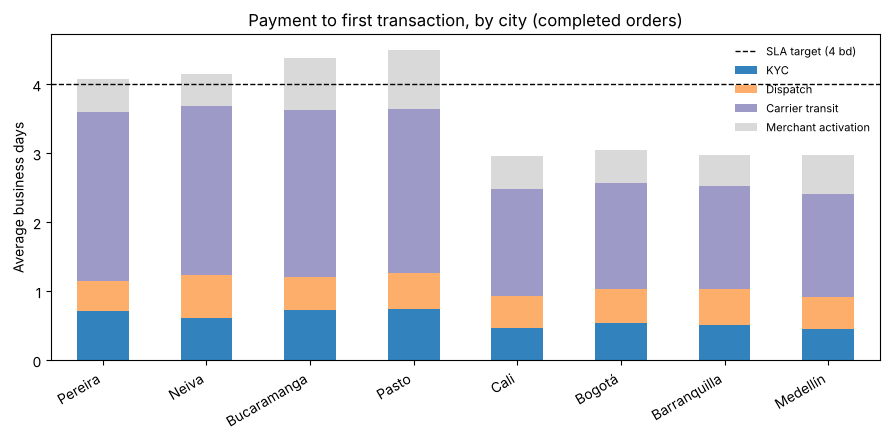

KYC  Dispatch  Carrier transit  \
city_tier    city                                            
intermediate Pereira       0.72      0.43             2.44   
             Neiva         0.61      0.63             2.44   
             Bucaramanga   0.73      0.48             2.42   
             Pasto         0.74      0.52             2.38   
major        Cali          0.47      0.46             1.56   
             Bogotá        0.54      0.49             1.54   
             Barranquilla  0.52      0.51             1.49   
             Medellín      0.46      0.46             1.49   

                           Merchant activation  
city_tier    city                               
intermediate Pereira                      0.48  
             Neiva                        0.47  
             Bucaramanga                  0.76  
             Pasto                        0.86  
major        Cali                         0.48  
             Bogotá                       0.48  
             Barranquilla                 0.46  
             Medellín                     0.56

In [6]:
STAGES = {"bd_kyc": "KYC", "bd_dispatch": "Dispatch", "bd_transit": "Carrier transit", "bd_activation": "Merchant activation"}
by_city = done.groupby(["city_tier", "city"])[list(STAGES)].mean().rename(columns=STAGES)
by_city = by_city.sort_values("Carrier transit", ascending=False)   # sorted so the slowest cities are on the left
by_city.droplevel("city_tier").plot(kind="bar", stacked=True, figsize=(9, 4.5), colormap="tab20c")
plt.axhline(SLA_TARGET_BDAYS, color="black", linestyle="--", linewidth=1, label=f"SLA target ({SLA_TARGET_BDAYS} bd)")
plt.ylabel("Average business days"); plt.xlabel(""); plt.title("Payment to first transaction, by city (completed orders)")
plt.legend(frameon=False, fontsize=8); plt.xticks(rotation=30, ha="right"); plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sla_by_city.png", dpi=150); plt.show()
by_city.round(2)

### 5.2 Why are the severe delays happening?

For every order that took more than 6 business days, find the step that took the longest. If KYC were the main culprit we would see it here instead of the carrier.

In [7]:
severe = done[done["bd_total"] > SLA_SEVERE_BDAYS].copy()
severe["longest_step"] = severe[list(STAGES)].idxmax(axis=1).map(STAGES)
cause = severe.groupby(["city_tier", "longest_step"]).size().unstack(fill_value=0)
cause_pct = (cause.div(cause.sum(axis=1), axis=0) * 100).round(1)
print(f"{len(severe)} orders with a severe delay. Share by longest step (%):")
cause_pct

61 orders with a severe delay. Share by longest step (%):


longest_step,Carrier transit,KYC,Merchant activation
city_tier,,,
intermediate,54.1,27.9,18.0


### 5.3 KPIs

**Why two SLA numbers?** Counting only orders that already finished hides the worst cases: a device that never activates never appears in "completed". The honest version also counts open orders that are already past the target. The difference between the two numbers is the cost of that blind spot.

In [8]:
measured = df_orders[df_orders["sla_status"].isin(["Completed on time", "Completed late", "Open - already late"])]
sla_naive = (done["bd_total"] <= SLA_TARGET_BDAYS).mean()
sla_honest = (measured["sla_status"] == "Completed on time").mean()

limbo = int(df_orders["is_zombie_pos"].sum() + df_orders["is_stalled_in_transit"].sum())
active = int((df_orders["logistics_status"] == "Activated").sum())

reconcilable = df_recon[df_recon["reconciliation_status"] != "Pending - within window"]
exceptions = reconcilable[reconcilable["reconciliation_status"] != "Reconciled"]
recon_rate = (reconcilable["reconciliation_status"] == "Reconciled").mean()
capital_gap = int(exceptions["difference_cop"].abs().sum())
shortfall = int(-exceptions.loc[exceptions["difference_cop"] < 0, "difference_cop"].sum())
overcollected = int(exceptions.loc[exceptions["difference_cop"] > 0, "difference_cop"].sum())

kpis = pd.DataFrame([
    ("Activation SLA compliance (completed orders only)", f"{sla_naive:.1%}"),
    ("Activation SLA compliance (incl. open orders already late)", f"{sla_honest:.1%}"),
    ("POS activated", f"{active:,}"),
    ("POS in limbo (stalled in transit + delivered, not activated)", f"{limbo:,}"),
    ("Exact reconciliation rate", f"{recon_rate:.1%}"),
    ("Capital in discrepancy (COP, absolute)", f"{capital_gap:,}"),
    ("   of which money not received (COP)", f"{shortfall:,}"),
    ("   of which money received in excess (COP)", f"{overcollected:,}"),
], columns=["KPI", "Value"])
kpis.to_csv(OUTPUT_DIR / "kpis.csv", index=False)
kpis

,KPI,Value
0,Activation SLA compliance (completed orders only),86.5%
1,Activation SLA compliance (incl. open orders a...,77.2%
2,POS activated,"1,226"
3,"POS in limbo (stalled in transit + delivered, ...",87
4,Exact reconciliation rate,95.8%
5,"Capital in discrepancy (COP, absolute)","4,265,000"
6,of which money not received (COP),"2,494,000"
7,of which money received in excess (COP),"1,771,000"


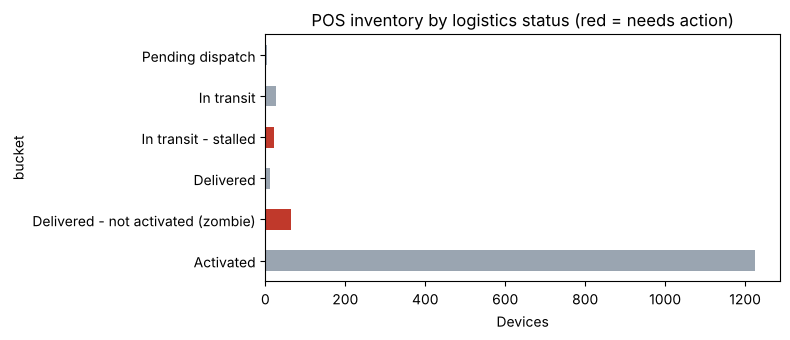

In [9]:
status_order = ["Pending dispatch", "In transit", "Delivered", "Activated"]
inv_view = df_orders[df_orders["logistics_status"].notna()].copy()
inv_view["bucket"] = np.select([inv_view["is_stalled_in_transit"] == 1, inv_view["is_zombie_pos"] == 1],
                               ["In transit - stalled", "Delivered - not activated (zombie)"], default=inv_view["logistics_status"])
counts = inv_view["bucket"].value_counts().reindex(
    ["Pending dispatch", "In transit", "In transit - stalled", "Delivered", "Delivered - not activated (zombie)", "Activated"]).dropna()
colors = ["#9aa5b1" if "stalled" not in k and "zombie" not in k else "#c0392b" for k in counts.index]
counts.plot(kind="barh", color=colors, figsize=(8, 3.5)); plt.gca().invert_yaxis()
plt.xlabel("Devices"); plt.title("POS inventory by logistics status (red = needs action)"); plt.tight_layout()
plt.savefig(OUTPUT_DIR / "pos_inventory.png", dpi=150); plt.show()

In [10]:
# Finance priority list: biggest peso impact first
priority = (exceptions.merge(df_orders[["order_id", "city", "sales_channel"]], on="order_id", how="left")
            .assign(abs_difference_cop=lambda d: d["difference_cop"].abs())
            .sort_values("abs_difference_cop", ascending=False))
priority[["order_id", "city", "reconciliation_status", "billed_cop", "collected_cop", "difference_cop"]].head(10)

,order_id,city,reconciliation_status,billed_cop,collected_cop,difference_cop
8,ORD-00336,Cali,Invoiced without collection,129000.0,0.0,-129000
16,ORD-00400,Cali,Amount difference - over-collected,129000.0,258000.0,129000
36,ORD-00893,Barranquilla,Invoiced without collection,129000.0,0.0,-129000
35,ORD-00868,Pasto,Amount difference - over-collected,129000.0,258000.0,129000
60,ORD-01401,Barranquilla,Collected without invoice,NaN,129000.0,129000
29,ORD-00722,Barranquilla,Invoiced without collection,99000.0,0.0,-99000
6,ORD-00262,Bucaramanga,Invoiced without collection,99000.0,0.0,-99000
37,ORD-00916,Neiva,Invoiced without collection,99000.0,NaN,-99000
53,ORD-01233,Barranquilla,Collected without invoice,NaN,99000.0,99000
52,ORD-01210,Barranquilla,Amount difference - over-collected,99000.0,198000.0,99000


## 6. Automation: exception report and ticket drafts

The report has one tab per owning team, so each team opens only what it has to act on:

| Tab | Owner | What is in it |
|---|---|---|
| `Logistics_Escalation` | Logistics | Devices in transit with no carrier update |
| `Finance_Collections` | Finance / collections | Every reconciliation break, biggest amount first |
| `Commercial_Onboarding` | Commercial / onboarding | Delivered but never activated, KYC pending too long, KYC rejected |

Every row gets a ready-to-send ticket text (in Spanish, because the recipients are carriers and merchants in Colombia).

**About the "AI" part, honestly.** The default tickets come from fixed templates, which is deterministic, free and auditable. `build_llm_prompt` shows how the same row would be turned into a prompt for a language model; pass any function that takes a prompt and returns text as `llm_call` and the template is replaced by the model's draft. The LLM path is not exercised in this notebook.

In [11]:
def fmt_cop(x):
    return f"-${abs(x):,.0f} COP" if x < 0 else f"${x:,.0f} COP"

def build_ticket(row):
    """Template-based ticket text. Returns (owner_team, subject, body)."""
    kind = row["exception_type"]
    n_ = lambda col: int(row[col]) if pd.notna(row[col]) else "?"   # whole numbers, not 114.0
    if kind == "Stalled in transit":
        return ("Logistics", f"Sin novedad de transportadora - pedido {row['order_id']}",
                f"El equipo {row['pos_model']} (serial {row['pos_serial']}) fue despachado el {row['dispatch_date']} con {row['carrier']} "
                f"hacia {row['city']} y no registra novedad hace {n_('days_since_carrier_update')} dias. "
                "Por favor confirmar ubicacion actual y fecha estimada de entrega, o abrir reclamo por perdida.")
    if kind == "Delivered, not activated":
        return ("Commercial / Onboarding", f"POS entregado sin activar - comercio {row['merchant_id']}",
                f"El equipo {row['pos_model']} fue entregado en {row['city']} hace {n_('days_since_delivery')} dias y el comercio no ha hecho su primera transaccion. "
                "Por favor contactar al comercio, confirmar que recibio el equipo y ofrecer acompanamiento para la configuracion.")
    if kind == "KYC pending too long":
        return ("Commercial / Onboarding", f"Validacion KYC pendiente - comercio {row['merchant_id']}",
                f"El comercio de {row['city']} pago hace {n_('bd_open_age')} dias habiles y su validacion sigue pendiente "
                f"(objetivo de activacion: {SLA_TARGET_BDAYS} dias habiles). Por favor revisar el expediente y resolver o solicitar la informacion que falta.")
    if kind == "KYC rejected":
        return ("Commercial / Onboarding", f"KYC rechazado - comercio {row['merchant_id']}",
                f"La validacion fue rechazada por: {row['kyc_rejection_reason']}. Por favor contactar al comercio para solicitar la documentacion corregida "
                "o gestionar la devolucion del pago si no es posible continuar.")
    # finance exceptions
    owner = "Finance / Collections"
    detail = f"Facturado: {fmt_cop(row['billed_cop'] if pd.notna(row['billed_cop']) else 0)}. Recaudado: {fmt_cop(row['collected_cop'] if pd.notna(row['collected_cop']) else 0)}. Diferencia: {fmt_cop(row['difference_cop'])}."
    action = {
        "Amount difference - under-collected": "Pago parcial. Verificar con el banco y contactar al comercio para el saldo.",
        "Amount difference - over-collected": "Posible cobro duplicado. Confirmar y gestionar la devolucion.",
        "Invoiced without collection": "No hay recaudo neto (no llego el pago o fue reversado). Verificar con el banco y gestionar el cobro.",
        "Collected without invoice": "Hay recaudo sin factura. Emitir la factura o identificar el origen del pago.",
    }[kind]
    return (owner, f"Descuadre de recaudo - pedido {row['order_id']}", f"{detail} {action}")

def build_llm_prompt(row):
    """Prompt that would be sent to a language model for one exception row."""
    facts = {k: (None if pd.isna(v) else v) for k, v in row.items()
             if k in {"order_id", "merchant_id", "city", "pos_model", "carrier", "exception_type", "days_since_delivery",
                      "days_since_carrier_update", "bd_open_age", "billed_cop", "collected_cop", "difference_cop", "kyc_rejection_reason"}}
    return ("Eres analista de operaciones comerciales en una fintech de pagos en Colombia. "
            "Redacta un ticket breve (maximo 70 palabras, en espanol, tono profesional) para el area responsable. "
            "Usa solo los datos dados, no inventes nada, e incluye la accion concreta que se pide.\n"
            f"Datos: {facts}")

def generate_ticket(row, llm_call=None):
    owner, subject, body = build_ticket(row)
    if llm_call is not None:                       # optional: replace the template with a model draft
        body = llm_call(build_llm_prompt(row))
    return pd.Series({"owner_team": owner, "ticket_subject": subject, "ticket_body": body})

# ---- assemble the three exception lists ----
logistics = df_orders[df_orders["is_stalled_in_transit"] == 1].assign(exception_type="Stalled in transit")
logistics = logistics.sort_values("days_since_carrier_update", ascending=False)

commercial = pd.concat([
    df_orders[df_orders["is_zombie_pos"] == 1].assign(exception_type="Delivered, not activated"),
    df_orders[(df_orders["kyc_status"] == "Pending") & (df_orders["bd_open_age"] > KYC_OVERDUE_BDAYS)].assign(exception_type="KYC pending too long"),
    df_orders[df_orders["kyc_status"] == "Rejected"].assign(exception_type="KYC rejected"),
]).sort_values(["exception_type", "bd_open_age"], ascending=[True, False])

finance = priority.rename(columns={"reconciliation_status": "exception_type"}).merge(
    df_orders[["order_id", "merchant_id", "pos_model"]], on="order_id", how="left")

report_cols = {
    "Logistics_Escalation": (logistics, ["order_id", "pos_serial", "pos_model", "carrier", "city", "dispatch_date",
                                         "carrier_last_update_date", "days_since_carrier_update"]),
    "Finance_Collections": (finance, ["order_id", "merchant_id", "city", "invoice_date", "billed_cop", "collected_cop",
                                      "difference_cop", "n_bank_rows"]),
    "Commercial_Onboarding": (commercial, ["order_id", "merchant_id", "city", "sales_channel", "kyc_status", "kyc_rejection_reason",
                                           "logistics_status", "days_since_delivery", "bd_open_age"]),
}

report_path = OUTPUT_DIR / "Ops_Exceptions_Report.xlsx"
with pd.ExcelWriter(report_path, engine="openpyxl") as writer:
    for sheet, (df, cols) in report_cols.items():
        tickets = df.apply(generate_ticket, axis=1)
        out = pd.concat([df[["exception_type"]], df[cols], tickets], axis=1)
        out.to_excel(writer, sheet_name=sheet, index=False)
        ws = writer.sheets[sheet]
        ws.freeze_panes = "A2"
        for column in ws.columns:
            letter = column[0].column_letter
            width = min(max(len(str(c.value)) if c.value is not None else 0 for c in column[:50]) + 2, 60)
            ws.column_dimensions[letter].width = width
        print(f"{sheet}: {len(out)} rows")

print("Saved", report_path)
print()
print(generate_ticket(logistics.iloc[0])["ticket_body"])

Logistics_Escalation: 22 rows
Finance_Collections: 63 rows
Commercial_Onboarding: 205 rows
Saved output/Ops_Exceptions_Report.xlsx

El equipo Bold Smart (serial SN97649360) fue despachado el 2026-09-15 con Inter Rapidísimo hacia Pasto y no registra novedad hace 44 dias. Por favor confirmar ubicacion actual y fecha estimada de entrega, o abrir reclamo por perdida.


### Export for the dashboard

Looker Studio or Power BI can read these CSV files directly. One row per order, with the reconciliation status attached.

In [12]:
master = df_orders.merge(df_recon[["order_id", "billed_cop", "collected_cop", "difference_cop", "reconciliation_status"]],
                         on="order_id", how="left")
master.to_csv(OUTPUT_DIR / "orders_master.csv", index=False)
print(len(master), "rows ->", OUTPUT_DIR / "orders_master.csv")
conn.close()

1500 rows -> output/orders_master.csv


## Limitations

* Synthetic data and a simplified world: one order per merchant, weekends are the only non-business days (Colombian holidays are ignored), no VAT or fees.
* Device names and prices are placeholders, not official figures.
* The dashboard is **not** built here. The three CSV files in `output/` are what it would read; a mock-up or screenshot should only be added once it is really built.
* `julianday` and the `OVER` window syntax work in SQLite. Moving this to BigQuery or PostgreSQL means swapping the date functions (`DATE_DIFF`, `CURRENT_DATE`), and the logic stays the same.
* The LLM ticket path is a design sketch and has not been run.